# 03 · Paint by number

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/james-kidd/pbn-notebooks/blob/main/notebooks/03_paint_by_number.ipynb)

The original application, assembled from its parts rather than called as
one function — so each stage's contribution is visible.

This is the strongest of the three applications in the toolkit, for one
reason worth naming: **it has an objective quality metric.** The original
image is right there to compare against. The land-use labelling has no
such thing, which is why it stays framed as a feature layer rather than a
classifier.

The scene here is `scenes.landscape()` rather than the flat parcel scenes
the other notebooks use — quantising an image that is already twelve flat
colours proves nothing.

In [1]:
# Bootstrap: clones what it needs in Colab, finds what exists locally.
import pathlib, subprocess, sys

def _repo_root():
    for base in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
        if (base / "nbtools" / "bootstrap.py").exists():
            return base
    dest = (pathlib.Path("/content/pbn-notebooks") if pathlib.Path("/content").is_dir()
            else pathlib.Path.cwd() / "pbn-notebooks")
    if not (dest / "nbtools").exists():
        subprocess.run(["git", "clone", "--depth", "1", "--quiet",
                        "https://github.com/james-kidd/pbn-notebooks.git", str(dest)],
                       check=True)
    return dest

sys.path.insert(0, str(_repo_root()))
from nbtools.bootstrap import setup

tk = setup()                           # installs anything missing, first
from nbtools import scenes, display    # these need cv2/matplotlib, so: after

toolkit   /home/user/pbn-gradio  (found locally)
modules   geo, land_use, optimize, pipeline, segmenters, siting, topology
gradio    stubbed (UI layer not needed for these demos)


## Stages 1–2 · Preprocess and segment

RGB to CIELAB, bilateral filter (smooths noise, keeps edges), then
segment.

slic → drop<480px (751 regions)


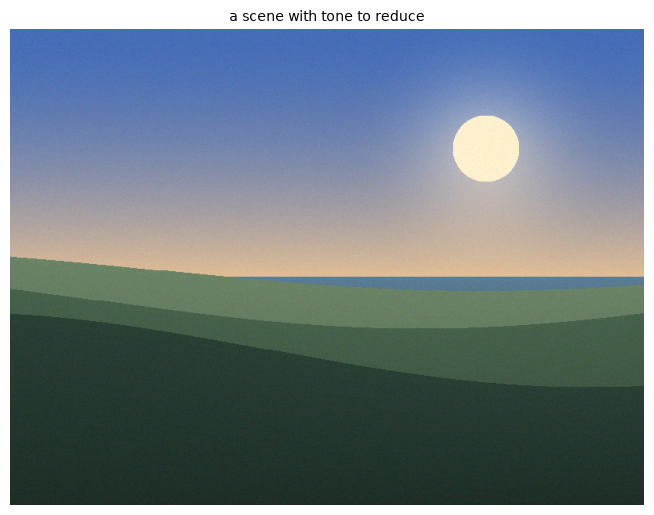

In [2]:
image = scenes.landscape()
working = tk.pipeline.load_and_resize(image, 800)
lab = tk.pipeline.preprocess_rgb(working)
MIN_AREA = int(working.shape[0] * working.shape[1] * 0.001)

seg = tk.segmenters.segment(lab, "slic", merge_threshold=None, min_area=MIN_AREA,
                            n_segments=1000, compactness=12.0, sigma=2.0)
print(seg.describe())
display.show(working, "a scene with tone to reduce", width=7)

### Why merging is switched off here

Every other notebook merges aggressively. This one passes
`merge_threshold=None`, and the reason is worth knowing.

RAG merging collapses adjacent regions closer than the threshold — and it
**cascades**. On a smooth gradient, superpixel A is within threshold of B,
their merged region is within threshold of C, and so on until the entire
sky is one region. Merging this scene at a threshold of 4 takes it from
751 regions to 8.

Correct behaviour for parcels, where you *want* a field to be one region.
Fatal for a paint-by-number template, whose whole job is to reduce
continuous tone into bands.

## Stage 3 · Palette

k-means over the *region mean colours*, not over pixels. Clustering in
LAB rather than RGB keeps the palette perceptually balanced: colours that
look similar group together, rather than colours that happen to share raw
channel values.

In [3]:
PALETTE_SIZE = 12
indexed, palette_lab = tk.pipeline.quantize_palette(lab, seg.labels, PALETTE_SIZE)
print(f"{len(palette_lab)} palette colours from {seg.n_regions} regions")

12 palette colours from 751 regions


## Stage 4 · Contiguity

Connected-component analysis over the indexed image. This is what
guarantees each numbered area is a single piece — a requirement for a
physically paintable template, and not something the palette step
provides on its own.

In [4]:
final_labels, region_to_colour = tk.pipeline.final_connectivity(indexed, MIN_AREA)
print(f"{len(region_to_colour)} contiguous paint regions")

53 contiguous paint regions


## Stage 5 · Render

Numbers are placed at each region's **distance-transform maximum** — the
point furthest from every boundary, so the digit is never clipped by an
edge.

That same primitive reappears in notebook 06 as the point of maximum
setback for siting a building. Identical computation, different question.

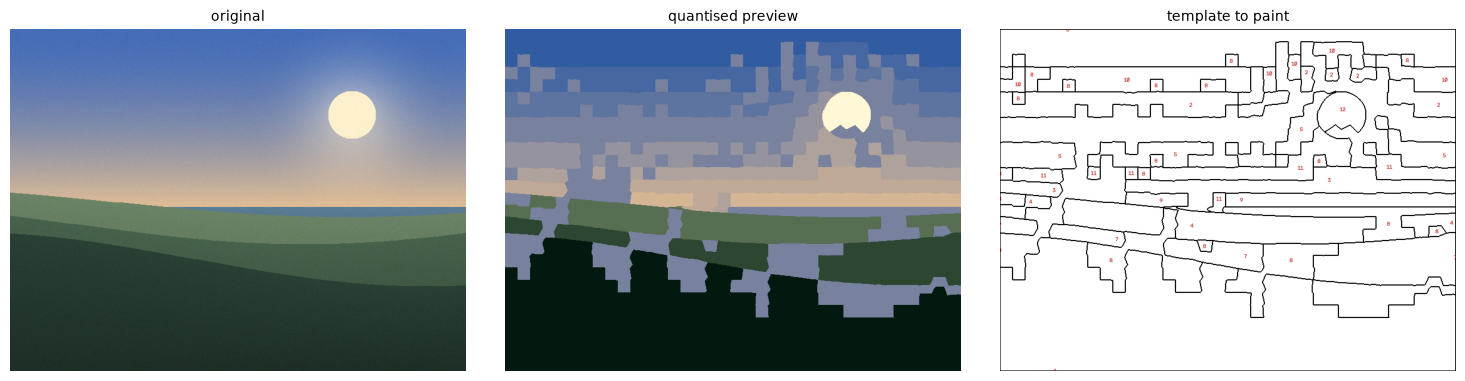

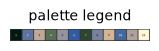

In [5]:
fill_img, outline_img, numbers, palette_rgb = tk.pipeline.render_outputs(
    final_labels, palette_lab, region_to_colour)
numbered = tk.pipeline.draw_numbers_on_outline(outline_img, numbers)
swatch = tk.pipeline.draw_palette_swatch(palette_rgb, PALETTE_SIZE)

display.grid([working, fill_img, numbered],
             ["original", "quantised preview", "template to paint"],
             columns=3, width=15)
display.show(swatch, "palette legend", width=7)

## The parameter that matters

Palette size is the real dial: it trades fidelity against how much work
the template is to paint. More colours track the original more closely
and take longer; fewer read as posterised.

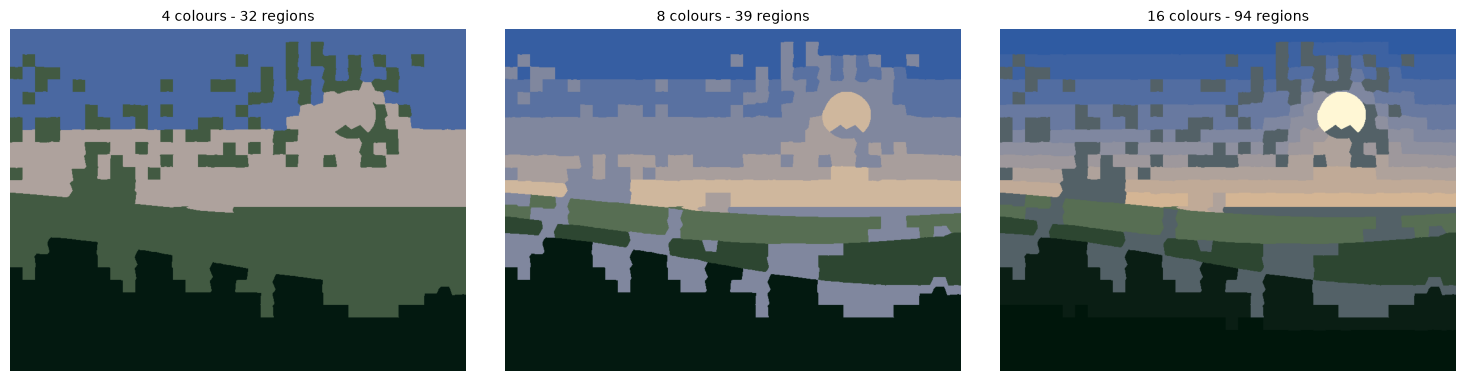

In [6]:
previews, captions = [], []
for k in (4, 8, 16):
    idx, pal = tk.pipeline.quantize_palette(lab, seg.labels, k)
    fl, r2c = tk.pipeline.final_connectivity(idx, MIN_AREA)
    preview, _, _, _ = tk.pipeline.render_outputs(fl, pal, r2c)
    previews.append(preview)
    captions.append(f"{k} colours - {len(r2c)} regions")

display.grid(previews, captions, columns=3, width=15)

Region count rises with palette size because contiguity is enforced
*after* quantisation: a finer palette splits areas that a coarser one
merged, and each split piece becomes its own numbered region.